# Домашняя работа 4 "Численное интегрирование функции"
**Колпакова Дарья Сергеевна, группа J3112, ИСУ 501390**

**Вариант 11**

Функция: $$ f(x) = \frac{1}{3} + \cos(10 + 2.3^{|x|}) $$

Интервал: $$ x \in [-1; 2.5] $$

### Используемые методы

Для вычисления определенного интеграла буду использовать два метода:
1. **Метод прямоугольников** (формула центральных прямоугольников).
2. **Метод Симпсона** (формула парабол).

**Метод центральных прямоугольников:**
$$ I_ц = h \sum_{i=0}^{N-1} f\left(x_i + \frac{h}{2}\right) $$
где $N$ — число отрезков разбиения, $h = \frac{b - a}{N}$, $x_i = a + i \cdot h$.

**Составная Формула Симпсона:**
$$ I_С = \frac{h}{3} \left( f(a) + 4 \sum_{i=0}^{\frac{N}{2}-1} f(x_{2i+1}) + 2 \sum_{i=1}^{\frac{N}{2}-1} f(x_{2i}) + f(b) \right) $$
где $N$ — четное число отрезков разбиения, $h = \frac{b - a}{N}$.

Результаты численного интегрирования:

     n |      Метод центр. прямоуг. |       Метод Симпсона
-----------------------------------------------------------
    10 |               2.2650900135 |         2.2422828519
   100 |               2.2924595087 |         2.2928921293
  1000 |               2.2928363916 |         2.2928402516


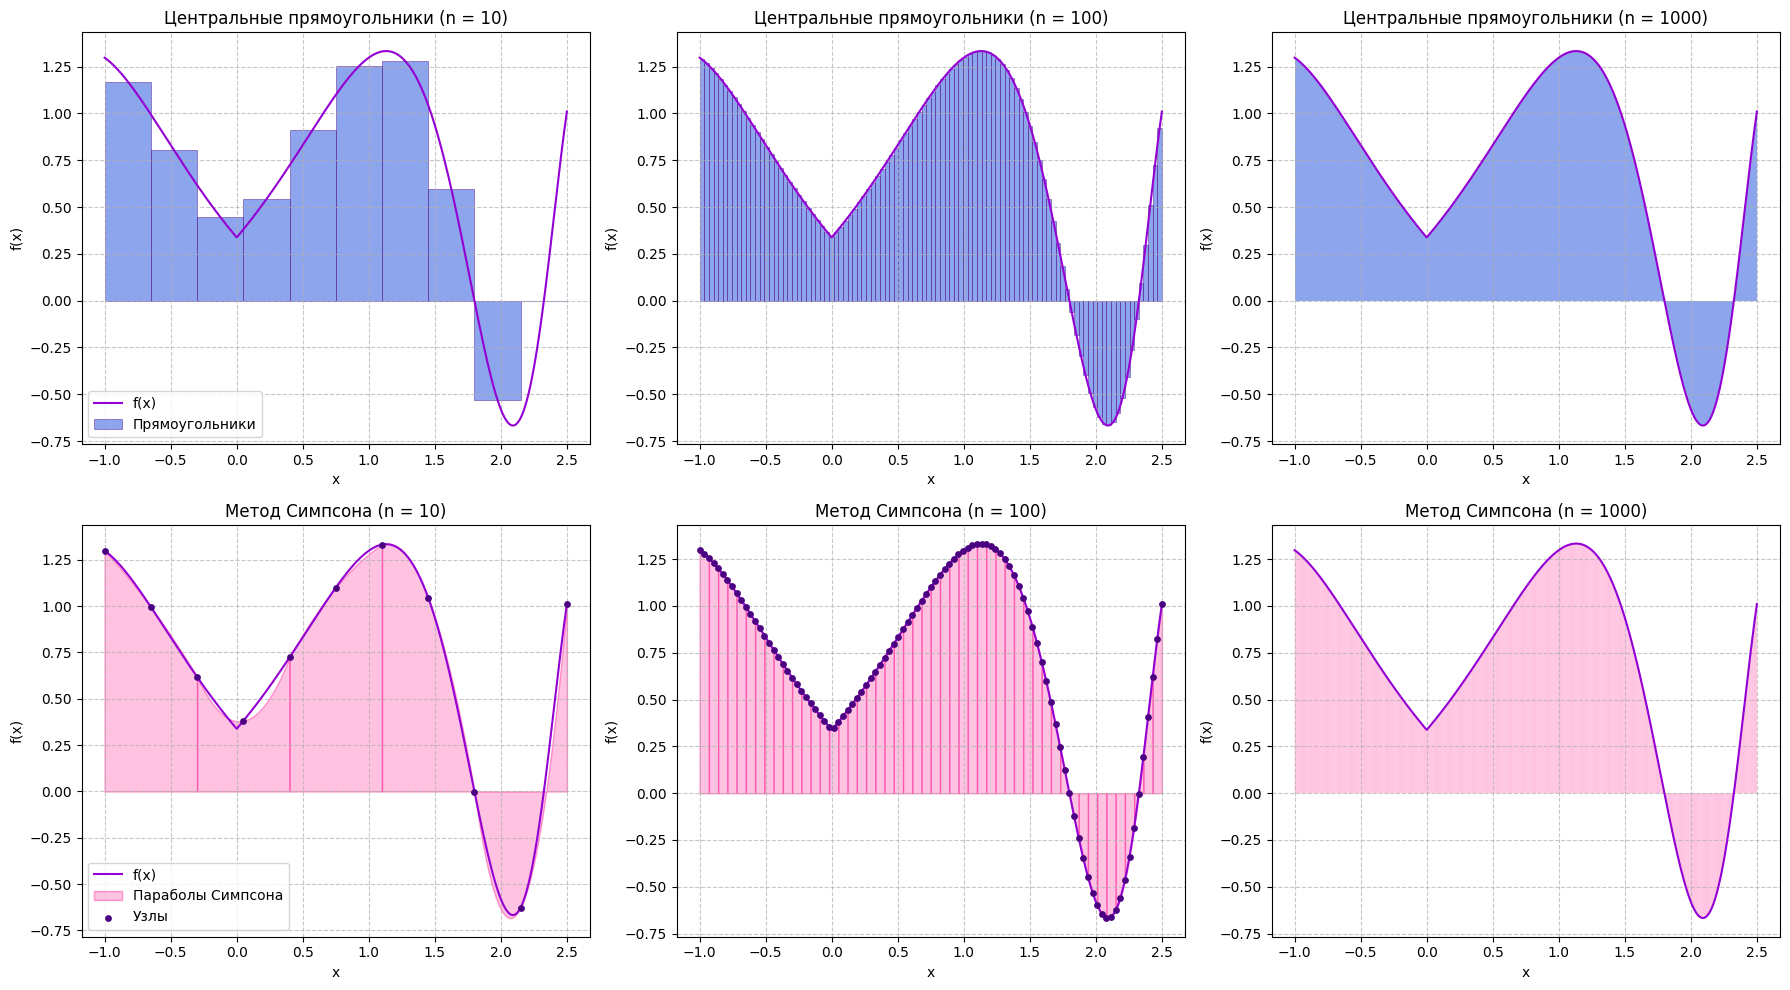

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Исходная функция (Вариант 11)
def f(x):
    return 1/3 + np.cos(10 + 2.3**np.abs(x))

# Заданный интервал
a = -1
b = 2.5
# Разное количество отрезков разбиения
n_list = [10, 100, 1000]

def divide_interval(a, b, n):
    return np.linspace(a, b, n + 1)

# Метод прямоугольников
def midpoint_rectangle_integration(a, b, n):
    h = (b - a) / n
    # Узлы в серединах отрезков: от a+h/2 до b-h/2
    x_mid = np.linspace(a + h/2, b - h/2, n)
    fx = f(x_mid)
    I = h * np.sum(fx)
    return I, fx

# Метод Симпсона (парабол)
def simpson_integration(a, b, n):
    if n % 2 != 0:
        n += 1 # Для метода Симпсона n должно быть четным
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)

    # Формула Симпсона
    I = h / 3 * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[-1])
    return I

print("Результаты численного интегрирования:\n")
print(f"{'n':>6} | {'Метод центр. прямоуг.':>26} | {'Метод Симпсона':>20}")
print("-" * 59)

for n in n_list:
    I_mid, _ = midpoint_rectangle_integration(a, b, n)
    I_simp = simpson_integration(a, b, n)
    print(f"{n:6} | {I_mid:26.10f} | {I_simp:20.10f}")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
x_dense = np.linspace(a, b, 1000)
y_dense = f(x_dense)

for i, n in enumerate(n_list):
    ax_rand = axes[0, i]

    # Вычисляем значения для графика
    I_mid, fx_mid = midpoint_rectangle_integration(a, b, n)
    z = divide_interval(a, b, n)

    # График функции
    ax_rand.plot(x_dense, y_dense, color="darkviolet", label="f(x)", zorder=2)

    # График прямоугольников
    ax_rand.bar(z[:-1], fx_mid, width=(b - a) / n, align="edge", color="royalblue", alpha=0.6,
            edgecolor='indigo' if n <= 100 else 'none', linewidth=0.5, label='Прямоугольники', zorder=1)

    ax_rand.set_xlabel("x")
    ax_rand.set_ylabel("f(x)")
    ax_rand.set_title(f"Центральные прямоугольники (n = {n})")
    ax_rand.grid(True, linestyle='--', alpha=0.7)

    if i == 0:
        ax_rand.legend()

    ax_simp = axes[1, i]
    ax_simp.plot(x_dense, y_dense, color="darkviolet", label="f(x)", zorder=2)

    n_simp = n if n % 2 == 0 else n + 1
    x_nodes = np.linspace(a, b, n_simp + 1)
    y_nodes = f(x_nodes)

    # Отрисовка парабол Симпсона
    for j in range(0, n_simp, 2):
        x_sub = x_nodes[j:j+3]
        y_sub = y_nodes[j:j+3]
        # Строим параболу по 3 точкам
        p = np.polyfit(x_sub, y_sub, 2)
        x_par = np.linspace(x_sub[0], x_sub[-1], 50)
        y_par = np.polyval(p, x_par)

        label_par = "Параболы Симпсона" if j == 0 else ""
        ax_simp.fill_between(x_par, 0, y_par, color="hotpink", alpha=0.4,
                             edgecolor='deeppink' if n <= 100 else 'none', linewidth=1, zorder=1, label=label_par)

    # Отрисовка узлов только для малых N
    if n <= 100:
        ax_simp.scatter(x_nodes, y_nodes, color="indigo", s=15, zorder=3, label="Узлы")

    ax_simp.set_xlabel("x")
    ax_simp.set_ylabel("f(x)")
    ax_simp.set_title(f"Метод Симпсона (n = {n_simp})")
    ax_simp.grid(True, linestyle='--', alpha=0.7)

    if i == 0:
        ax_simp.legend()

plt.tight_layout()
plt.show()